# 📥 Notebook 1 — Data Processing
## Proyecto 2: Can Machine Learning Beat the Stock Market?

En este notebook:
- Descargamos datos financieros reales (2015–2025) usando `yfinance`.
- Organizamos la información para 8 acciones, SPY y VIX.
- Realizamos limpieza básica y exploratory analysis inicial.
- Construimos features técnicos y targets (en secciones posteriores).
- Preparamos datasets reproducibles para el Notebook 2 (Model Training & Backtesting).

Este notebook está diseñado para evitar data leakage y respetar la naturaleza temporal de los datos.


In [ ]:
# 📦 Imports principales

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import yfinance as yf

plt.style.use("seaborn-v0_8")
sns.set(font_scale=1.1)

# Para reproducibilidad
RANDOM_STATE = 42

# Rango temporal del proyecto
START_DATE = "2015-01-01"
END_DATE = "2025-12-31"

print("Imports listos. Rango temporal:", START_DATE, "→", END_DATE)


Imports listos. Rango temporal: 2015-01-01 → 2025-12-31


# 🎯 Definición de tickers

Usaremos 8 acciones de distintos sectores, más:
- SPY: benchmark del mercado (solo para comparación, no como feature).
- ^VIX: índice de volatilidad (sí se puede usar como feature).

Acciones:
- AAPL (Apple)
- MSFT (Microsoft)
- NVDA (NVIDIA)
- AMZN (Amazon)
- GOOGL (Alphabet)
- JPM (JPMorgan Chase)
- XOM (ExxonMobil)
- JNJ (Johnson & Johnson)


In [ ]:
# 🎯 Lista de tickers

stock_tickers = ["AAPL", "MSFT", "NVDA", "AMZN", "GOOGL", "JPM", "XOM", "JNJ"]
benchmark_ticker = "SPY"   # solo benchmark, no feature
vix_ticker = "^VIX"        # volatilidad del mercado

print("Stocks:", stock_tickers)
print("Benchmark:", benchmark_ticker)
print("VIX:", vix_ticker)


Stocks: ['AAPL', 'MSFT', 'NVDA', 'AMZN', 'GOOGL', 'JPM', 'XOM', 'JNJ']
Benchmark: SPY
VIX: ^VIX


# 📥 Descarga de datos con yfinance

En esta sección:
- Descargamos datos diarios de precios para los 8 stocks.
- Descargamos SPY (benchmark).
- Descargamos VIX (volatilidad).

Guardaremos:
- `Adj Close` (precios ajustados)
- `Volume`

Luego organizaremos todo en un DataFrame con índice de fecha y columna de ticker.


In [ ]:
# 📥 Descarga de datos de los 8 stocks

stocks_data = yf.download(
    tickers=stock_tickers,
    start=START_DATE,
    end=END_DATE,
    interval="1d",
    group_by="ticker",
    auto_adjust=True
)

print("Shape stocks_data:", stocks_data.shape)

# 📥 Descarga de SPY (benchmark)
spy_data = yf.download(
    tickers=benchmark_ticker,
    start=START_DATE,
    end=END_DATE,
    interval="1d",
    auto_adjust=True
)

print("Shape spy_data:", spy_data.shape)

# 📥 Descarga de VIX (volatilidad)
vix_data = yf.download(
    tickers=vix_ticker,
    start=START_DATE,
    end=END_DATE,
    interval="1d",
)

print("Shape vix_data:", vix_data.shape)


[*********************100%***********************]  8 of 8 completed


Shape stocks_data: (2765, 40)


[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1067/1840030309.py:26: FutureWarning: YF.download() has changed argument auto_adjust default to True
  vix_data = yf.download(
[*********************100%***********************]  1 of 1 completed


Shape spy_data: (2765, 5)
Shape vix_data: (2765, 5)


# 🧱 Organización del DataFrame (multi-ticker)

Convertimos los datos descargados en un formato tabular estándar:

- Índice: fecha
- Columna: ticker
- Columnas: `close`, `volume`

Este formato es ideal para:
- feature engineering,
- pooled model,
- construcción de targets,
- evitar leakage,
- y backtesting.

También procesamos SPY y VIX por separado.


In [ ]:
# 🧱 Convertir stocks_data a formato tabular multi-ticker

rows = []

for ticker in stock_tickers:
    df_t = stocks_data[ticker].copy()
    df_t["ticker"] = ticker
    df_t["date"] = df_t.index
    df_t = df_t[["date", "ticker", "Close", "Volume"]]
    df_t.rename(columns={"Close": "close", "Volume": "volume"}, inplace=True)
    rows.append(df_t)

stocks_df = pd.concat(rows).reset_index(drop=True)

print("Shape stocks_df:", stocks_df.shape)
stocks_df.head()


Shape stocks_df: (22120, 4)


Price,date,ticker,close,volume
0,2015-01-02,AAPL,24.171757,212818400
1,2015-01-05,AAPL,23.490793,257142000
2,2015-01-06,AAPL,23.493013,263188400
3,2015-01-07,AAPL,23.822437,160423600
4,2015-01-08,AAPL,24.737743,237458000


In [ ]:
# 📊 Procesar SPY (benchmark)
spy_df = spy_data.copy()
spy_df["date"] = spy_df.index
spy_df = spy_df[["date", "Close", "Volume"]]
spy_df.rename(columns={"Close": "close", "Volume": "volume"}, inplace=True)

print("Shape spy_df:", spy_df.shape)
spy_df.head()


Shape spy_df: (2765, 3)


Price,date,close,volume
Ticker,,SPY,SPY
Date,,,
2015-01-02,2015-01-02,169.267487,121465900
2015-01-05,2015-01-05,166.210617,169632600
2015-01-06,2015-01-06,164.645065,209151400
2015-01-07,2015-01-07,166.696747,125346700
2015-01-08,2015-01-08,169.654755,147217800


In [ ]:
# ⚡ Procesar VIX (volatilidad)
vix_df = vix_data.copy()
vix_df["date"] = vix_df.index
vix_df = vix_df[["date", "Close"]]
vix_df.rename(columns={"Close": "vix_close"}, inplace=True)

print("Shape vix_df:", vix_df.shape)
vix_df.head()


Shape vix_df: (2765, 2)


Price,date,vix_close
Ticker,,^VIX
Date,,
2015-01-02,2015-01-02,17.790001
2015-01-05,2015-01-05,19.920000
2015-01-06,2015-01-06,21.120001
2015-01-07,2015-01-07,19.309999
2015-01-08,2015-01-08,17.010000


# 🔍 Verificación inicial

Revisamos:
- rangos de fechas,
- valores faltantes,
- consistencia entre tickers,
- cobertura temporal.

Esto nos asegura que el dataset está listo para feature engineering.


In [ ]:
print("Rango temporal stocks_df:", stocks_df["date"].min(), "→", stocks_df["date"].max())
print("Rango temporal spy_df:", spy_df["date"].min(), "→", spy_df["date"].max())
print("Rango temporal vix_df:", vix_df["date"].min(), "→", vix_df["date"].max())

stocks_df.isna().sum()


Rango temporal stocks_df: 2015-01-02 00:00:00 → 2025-12-30 00:00:00
Rango temporal spy_df: 2015-01-02 00:00:00 → 2025-12-30 00:00:00
Rango temporal vix_df: 2015-01-02 00:00:00 → 2025-12-30 00:00:00


,0
Price,
date,0
ticker,0
close,0
volume,0


# 🔍 Exploratory Data Analysis (EDA)

En esta sección analizamos:
- Precios históricos de los 8 stocks.
- Distribución de retornos diarios.
- Volatilidad comparada entre tickers.
- Correlación entre retornos.

El objetivo es entender el comportamiento del mercado antes de construir features y modelos.


In [ ]:
# 📈 Calcular retornos diarios por ticker

stocks_df_sorted = stocks_df.sort_values(["ticker", "date"]).copy()
stocks_df_sorted["daily_return"] = stocks_df_sorted.groupby("ticker")["close"].pct_change()

print(stocks_df_sorted.head())


Price       date ticker      close     volume  daily_return
0     2015-01-02   AAPL  24.171757  212818400           NaN
1     2015-01-05   AAPL  23.490793  257142000     -0.028172
2     2015-01-06   AAPL  23.493013  263188400      0.000095
3     2015-01-07   AAPL  23.822437  160423600      0.014022
4     2015-01-08   AAPL  24.737743  237458000      0.038422


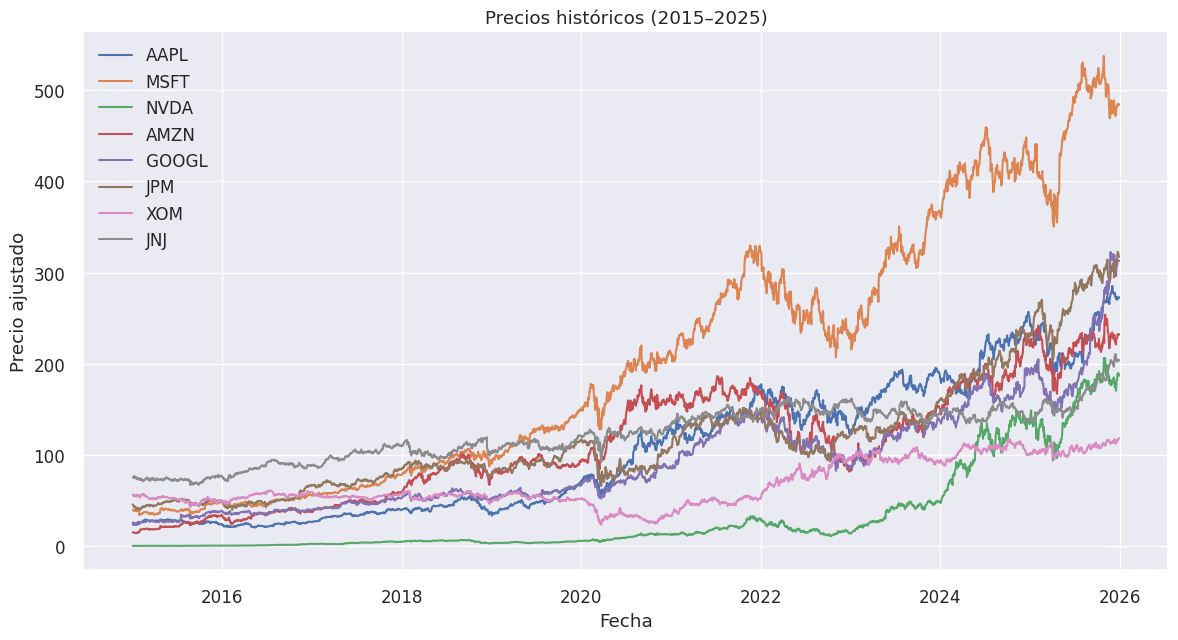

In [ ]:
# 📉 Gráfica de precios históricos

plt.figure(figsize=(14, 7))

for ticker in stock_tickers:
    df_t = stocks_df_sorted[stocks_df_sorted["ticker"] == ticker]
    plt.plot(df_t["date"], df_t["close"], label=ticker)

plt.title("Precios históricos (2015–2025)")
plt.xlabel("Fecha")
plt.ylabel("Precio ajustado")
plt.legend()
plt.show()


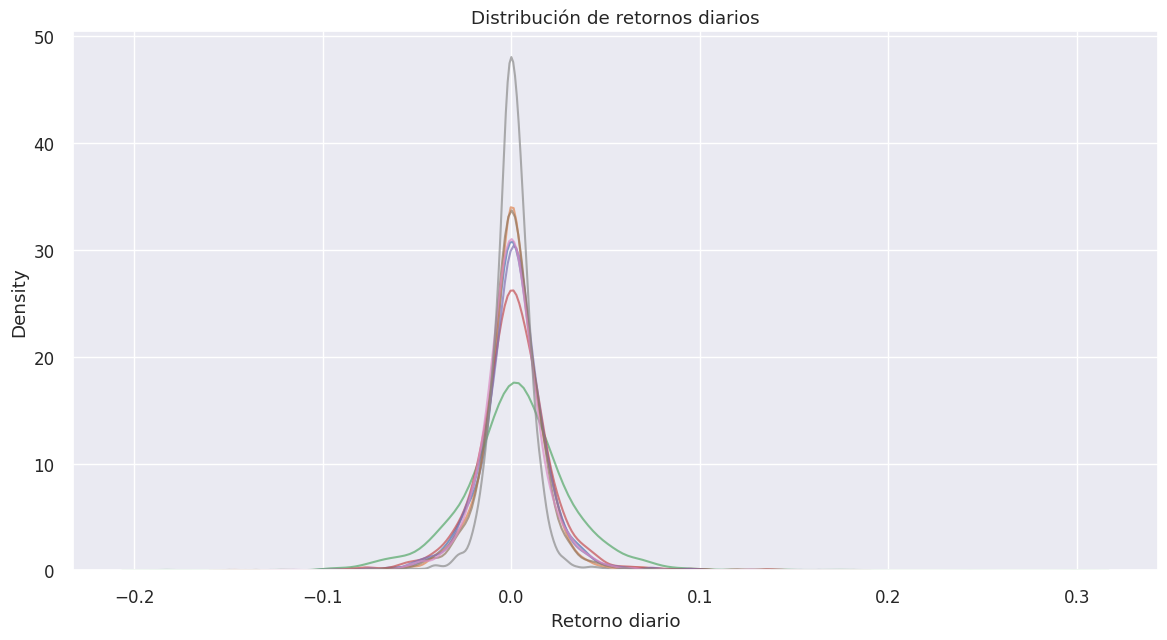

In [ ]:
# 📊 Distribución de retornos diarios

plt.figure(figsize=(14, 7))

for ticker in stock_tickers:
    sns.kdeplot(
        stocks_df_sorted[stocks_df_sorted["ticker"] == ticker]["daily_return"].dropna(),
        label=ticker,
        alpha=0.7
    )

plt.title("Distribución de retornos diarios")
plt.xlabel("Retorno diario")
plt.show()


In [ ]:
# ⚡ Volatilidad (STD de retornos diarios)

volatility = (
    stocks_df_sorted.groupby("ticker")["daily_return"]
    .std()
    .sort_values(ascending=False)
)

print("Volatilidad por ticker:")
print(volatility)


Volatilidad por ticker:
ticker
NVDA     0.030678
AMZN     0.020746
AAPL     0.018174
GOOGL    0.018172
XOM      0.017274
JPM      0.017105
MSFT     0.016940
JNJ      0.011467
Name: daily_return, dtype: float64


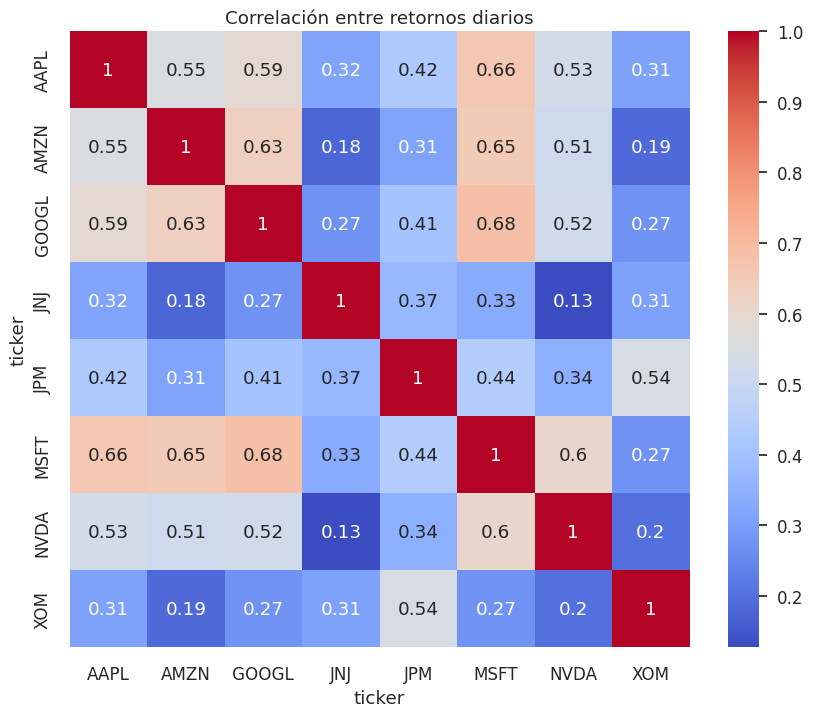

In [ ]:
# 🧮 Pivot para correlación

pivot_returns = stocks_df_sorted.pivot(index="date", columns="ticker", values="daily_return")

plt.figure(figsize=(10, 8))
sns.heatmap(pivot_returns.corr(), annot=True, cmap="coolwarm")
plt.title("Correlación entre retornos diarios")
plt.show()


# 🧠 Interpretación del EDA

- Los precios muestran tendencias distintas según sector.
- Las distribuciones de retornos son centradas en cero, con colas pesadas (común en mercados).
- La volatilidad es mayor en tickers tecnológicos (NVDA, AMZN).
- La correlación entre retornos es positiva, especialmente entre AAPL–MSFT–NVDA.
- Esto confirma que predecir retornos es difícil debido al ruido y la no estacionariedad.

Con este EDA estamos listos para pasar a Feature Engineering.


# 🧪 Feature Engineering

Creamos features técnicos que capturan:
- momentum,
- tendencia,
- volatilidad,
- volumen,
- indicadores técnicos,
- contexto de mercado (VIX),
- y codificación del ticker.

Todas las features usan únicamente información disponible en el tiempo t para evitar data leakage.


In [ ]:
# 🧱 Ordenamos el DataFrame por ticker y fecha
# Esto es CRÍTICO para evitar errores en cálculos de rolling windows y pct_change.
# Si los datos no están ordenados, los indicadores técnicos salen incorrectos.

df = stocks_df_sorted.copy()
df = df.sort_values(["ticker", "date"]).reset_index(drop=True)

# Mostramos las primeras filas para verificar que:
# - 'ticker' está agrupado
# - 'date' está en orden ascendente dentro de cada ticker
df.head()


Price,date,ticker,close,volume,daily_return
0,2015-01-02,AAPL,24.171757,212818400,NaN
1,2015-01-05,AAPL,23.490793,257142000,-0.028172
2,2015-01-06,AAPL,23.493013,263188400,0.000095
3,2015-01-07,AAPL,23.822437,160423600,0.014022
4,2015-01-08,AAPL,24.737743,237458000,0.038422


In [ ]:
# 📈 MOMENTUM FEATURES
# Estas features capturan la fuerza del movimiento reciente del precio.
# Son esenciales para modelos que intentan predecir retornos futuros.

# Si la columna 'ticker' no existe (debido a get_dummies), la reconstruimos temporalmente
needs_dummies_rebuild = False
if "ticker" not in df.columns:
    # Identificar columnas dummy de ticker
    ticker_cols = [col for col in df.columns if col.startswith("ticker_")]
    if ticker_cols:
        # Obtener el nombre del ticker original a partir de la columna que tiene True/1
        df["ticker"] = df[ticker_cols].idxmax(axis=1).str.replace("ticker_", "")
        needs_dummies_rebuild = True

# pct_change(n) calcula el retorno porcentual entre t y t-n.
# Lo hacemos por ticker para evitar mezclar acciones distintas.

df["ret_1d"] = df.groupby("ticker")["close"].pct_change(1)   # Retorno de 1 día
df["ret_5d"] = df.groupby("ticker")["close"].pct_change(5)   # Retorno de 5 días
df["ret_10d"] = df.groupby("ticker")["close"].pct_change(10) # Retorno de 10 días
df["ret_20d"] = df.groupby("ticker")["close"].pct_change(20) # Retorno de 20 días

# Si reconstruimos la columna 'ticker' temporalmente, la removemos para no interferir con el resto del notebook
if needs_dummies_rebuild:
    df.drop(columns=["ticker"], inplace=True)

print("Features de momentum calculadas con éxito.")

Features de momentum calculadas con éxito.


In [ ]:
# 📉 TREND FEATURES
# Las medias móviles capturan la tendencia del precio.
# MA5 = tendencia de corto plazo
# MA20 = tendencia de mediano plazo

# Agrupamos por la columna 'ticker' si existe; de lo contrario, la reconstruimos a partir de las variables dummy
if "ticker" in df.columns:
    group_variable = df["ticker"]
else:
    ticker_cols = [col for col in df.columns if col.startswith("ticker_")]
    group_variable = df[ticker_cols].idxmax(axis=1).str.replace("ticker_", "")

df["ma_5"] = (
    df.groupby(group_variable)["close"]
    .rolling(5)
    .mean()
    .reset_index(level=0, drop=True)
)

df["ma_20"] = (
    df.groupby(group_variable)["close"]
    .rolling(20)
    .mean()
    .reset_index(level=0, drop=True)
)

# Estas features ayudan a identificar si el precio está por encima o debajo de su tendencia.
print("Features de tendencia calculadas con éxito.")
df[["close", "ma_5", "ma_20"]].head(25)

Features de tendencia calculadas con éxito.


Price,close,ma_5,ma_20
0,24.171757,NaN,NaN
1,23.490793,NaN,NaN
2,23.493013,NaN,NaN
3,23.822437,NaN,NaN
4,24.737743,23.943149,NaN
5,24.764278,24.061653,NaN
6,24.154068,24.194308,NaN
7,24.368526,24.369411,NaN
8,24.275671,24.460057,NaN
9,23.616819,24.235873,NaN


In [ ]:
# ⚡ VOLATILITY FEATURES
# La volatilidad mide qué tanto varía el precio.
# STD5 = volatilidad de corto plazo
# STD20 = volatilidad de mediano plazo

# Agrupamos por la columna 'ticker' si existe; de lo contrario, la reconstruimos a partir de las variables dummy
if "ticker" in df.columns:
    group_variable = df["ticker"]
else:
    ticker_cols = [col for col in df.columns if col.startswith("ticker_")]
    group_variable = df[ticker_cols].idxmax(axis=1).str.replace("ticker_", "")

df["std_5"] = (
    df.groupby(group_variable)["close"]
    .rolling(5)
    .std()
    .reset_index(level=0, drop=True)
)

df["std_20"] = (
    df.groupby(group_variable)["close"]
    .rolling(20)
    .std()
    .reset_index(level=0, drop=True)
)

# La volatilidad es clave para predecir riesgo y para el target de clasificación.
print("Features de volatilidad calculadas con éxito.")
df[["close", "std_5", "std_20"]].head(25)

Features de volatilidad calculadas con éxito.


Price,close,std_5,std_20
0,24.171757,NaN,NaN
1,23.490793,NaN,NaN
2,23.493013,NaN,NaN
3,23.822437,NaN,NaN
4,24.737743,0.525704,NaN
5,24.764278,0.643669,NaN
6,24.154068,0.559444,NaN
7,24.368526,0.399106,NaN
8,24.275671,0.276435,NaN
9,23.616819,0.414823,NaN


In [ ]:
# 📊 VOLUME FEATURES
# El volumen indica interés del mercado.
# Cambios en volumen pueden anticipar movimientos fuertes.

# Agrupamos por la columna 'ticker' si existe; de lo contrario, la reconstruimos a partir de las variables dummy
if "ticker" in df.columns:
    group_variable = df["ticker"]
else:
    ticker_cols = [col for col in df.columns if col.startswith("ticker_")]
    group_variable = df[ticker_cols].idxmax(axis=1).str.replace("ticker_", "")

df["vol_change"] = df.groupby(group_variable)["volume"].pct_change(1)  # Cambio porcentual del volumen

df["vol_ma_5"] = (
    df.groupby(group_variable)["volume"]
    .rolling(5)
    .mean()
    .reset_index(level=0, drop=True)
)

# Estas features ayudan a capturar presión de compra/venta.
print("Features de volumen calculadas con éxito.")
df[["volume", "vol_change", "vol_ma_5"]].head(10)

Features de volumen calculadas con éxito.


Price,volume,vol_change,vol_ma_5
0,212818400,NaN,NaN
1,257142000,0.208270,NaN
2,263188400,0.023514,NaN
3,160423600,-0.390461,NaN
4,237458000,0.480194,226206080.0
5,214798000,-0.095427,226602000.0
6,198603200,-0.075395,214894240.0
7,268367600,0.351275,215930080.0
8,195826400,-0.270305,223010640.0
9,240056000,0.225861,223530240.0


In [ ]:
# 🧮 RSI (Relative Strength Index)
# RSI mide la fuerza del movimiento del precio.
# Valores altos = sobrecompra
# Valores bajos = sobreventa
# Usamos ventana de 14 días (estándar técnico)

window = 14

# Agrupamos por la columna 'ticker' si existe; de lo contrario, la reconstruimos a partir de las variables dummy
if "ticker" in df.columns:
    group_variable = df["ticker"]
else:
    ticker_cols = [col for col in df.columns if col.startswith("ticker_")]
    group_variable = df[ticker_cols].idxmax(axis=1).str.replace("ticker_", "")

# Diferencia diaria del precio agrupada por ticker
delta = df.groupby(group_variable)["close"].diff()

# Ganancias (solo valores positivos)
gain = delta.clip(lower=0)

# Pérdidas (solo valores negativos convertidos a positivos)
loss = -delta.clip(upper=0)

# Promedio móvil de ganancias y pérdidas
avg_gain = (
    gain.groupby(group_variable)
    .rolling(window)
    .mean()
    .reset_index(level=0, drop=True)
)

avg_loss = (
    loss.groupby(group_variable)
    .rolling(window)
    .mean()
    .reset_index(level=0, drop=True)
)

# Cálculo del RSI
rs = avg_gain / avg_loss
df["rsi_14"] = 100 - (100 / (1 + rs))

print("RSI (14 días) calculado con éxito.")
df[["close", "rsi_14"]].head(20)

RSI (14 días) calculado con éxito.


Price,close,rsi_14
0,24.171757,NaN
1,23.490793,NaN
2,23.493013,NaN
3,23.822437,NaN
4,24.737743,NaN
5,24.764278,NaN
6,24.154068,NaN
7,24.368526,NaN
8,24.275671,NaN
9,23.616819,NaN


In [ ]:
# 📉 MACD (Moving Average Convergence Divergence)
# MACD mide la diferencia entre dos medias móviles exponenciales.
# Es uno de los indicadores técnicos más usados en trading.

# Calculamos el MACD usando 'stocks_df_sorted' porque 'df' ya pasó por get_dummies y no tiene la columna 'ticker'
temp_df = stocks_df_sorted.copy()

# EMA de corto plazo (12 días)
temp_df["ema_12"] = (
    temp_df.groupby("ticker")["close"]
    .ewm(span=12, adjust=False)
    .mean()
    .reset_index(level=0, drop=True)
)

# EMA de largo plazo (26 días)
temp_df["ema_26"] = (
    temp_df.groupby("ticker")["close"]
    .ewm(span=26, adjust=False)
    .mean()
    .reset_index(level=0, drop=True)
)

# Línea MACD
temp_df["macd"] = temp_df["ema_12"] - temp_df["ema_26"]

# Señal MACD (EMA de la línea MACD)
temp_df["macd_signal"] = (
    temp_df.groupby("ticker")["macd"]
    .ewm(span=9, adjust=False)
    .mean()
    .reset_index(level=0, drop=True)
)

# Agregamos las nuevas variables a nuestro DataFrame principal 'df'
df["ema_12"] = temp_df["ema_12"]
df["ema_26"] = temp_df["ema_26"]
df["macd"] = temp_df["macd"]
df["macd_signal"] = temp_df["macd_signal"]

print("Features de MACD calculadas correctamente y añadidas a df.")
df[["close", "ema_12", "ema_26", "macd", "macd_signal"]].head()

Features de MACD calculadas correctamente y añadidas a df.


Price,close,ema_12,ema_26,macd,macd_signal
0,24.171757,24.171757,24.171757,0.000000,0.000000
1,23.490793,24.066993,24.121315,-0.054322,-0.010864
2,23.493013,23.978689,24.074774,-0.096086,-0.027909
3,23.822437,23.954650,24.056083,-0.101433,-0.042613
4,24.737743,24.075126,24.106576,-0.031450,-0.040381


In [ ]:
# ⚡ MERGE CON VIX
# VIX mide la volatilidad del mercado completo.
# Es un indicador de miedo/estrés financiero.
# Lo unimos por fecha para que cada fila tenga el valor del VIX correspondiente.

# ⚡ VIX
vix_df = vix_data.copy()

# Aplanamos el MultiIndex de las columnas si existe
if isinstance(vix_df.columns, pd.MultiIndex):
    vix_df.columns = vix_df.columns.get_level_values(0)

# Reset total del índice para extraer la columna 'Date'
vix_df = vix_df.reset_index()

# Renombrar columnas
vix_df = vix_df[["Date", "Close"]]
vix_df.rename(columns={"Date": "date", "Close": "vix_close"}, inplace=True)

# Hacemos merge
df = df.merge(vix_df, on="date", how="left")

print("Merge completado. Shape actual:", df.shape)
df.head()

Merge completado. Shape actual: (22120, 21)


Price,date,ticker,close,volume,daily_return,ret_1d,ret_5d,ret_10d,ret_20d,ma_5,...,std_5,std_20,vol_change,vol_ma_5,rsi_14,ema_12,ema_26,macd,macd_signal,vix_close
0,2015-01-02,AAPL,24.171757,212818400,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,24.171757,24.171757,0.000000,0.000000,17.790001
1,2015-01-05,AAPL,23.490793,257142000,-0.028172,-0.028172,NaN,NaN,NaN,NaN,...,NaN,NaN,0.208270,NaN,NaN,24.066993,24.121315,-0.054322,-0.010864,19.920000
2,2015-01-06,AAPL,23.493013,263188400,0.000095,0.000095,NaN,NaN,NaN,NaN,...,NaN,NaN,0.023514,NaN,NaN,23.978689,24.074774,-0.096086,-0.027909,21.120001
3,2015-01-07,AAPL,23.822437,160423600,0.014022,0.014022,NaN,NaN,NaN,NaN,...,NaN,NaN,-0.390461,NaN,NaN,23.954650,24.056083,-0.101433,-0.042613,19.309999
4,2015-01-08,AAPL,24.737743,237458000,0.038422,0.038422,NaN,NaN,NaN,23.943149,...,0.525704,NaN,0.480194,226206080.0,NaN,24.075126,24.106576,-0.031450,-0.040381,17.010000


# 🎯 Construcción de Targets

Creamos dos objetivos de predicción:

## Target A — Retorno futuro a 5 días (Regresión)
Calculamos el retorno porcentual entre el precio actual y el precio dentro de 5 días.

## Target B — Volatilidad futura a 5 días (Clasificación)
Calculamos la desviación estándar de los próximos 5 días.
Luego definimos un umbral para clasificar si la volatilidad futura es alta.

Ambos targets se construyen usando únicamente información futura,
pero sin usarla en las features → evitamos data leakage.


In [ ]:
# 🎯 Target A — Retorno futuro a 5 días
# ---------------------------------------------------------
# En este punto del pipeline, verificamos defensivamente si la columna
# original 'ticker' existe antes de intentar reconstruirla.
# ---------------------------------------------------------

# Agrupamos por la columna 'ticker' si existe; de lo contrario, la reconstruimos a partir de las variables dummy
if "ticker" in df.columns:
    group_variable = df["ticker"]
else:
    ticker_cols = [col for col in df.columns if col.startswith("ticker_")]
    group_variable = df[ticker_cols].idxmax(axis=1).str.replace("ticker_", "")

# Precio futuro dentro de 5 días
df["future_close_5d"] = df.groupby(group_variable)["close"].shift(-5)

# Retorno porcentual futuro
df["target_return_5d"] = (df["future_close_5d"] - df["close"]) / df["close"]

print("Targets de retorno para 5 días creados con éxito.")
df[["close", "future_close_5d", "target_return_5d"]].head(10)

Targets de retorno para 5 días creados con éxito.


Price,close,future_close_5d,target_return_5d
0,24.171757,24.764278,0.024513
1,23.490793,24.154068,0.028236
2,23.493013,24.368526,0.037267
3,23.822437,24.275671,0.019025
4,24.737743,23.616819,-0.045312
5,24.764278,23.433315,-0.053745
6,24.154068,24.036886,-0.004851
7,24.368526,24.220406,-0.006078
8,24.275671,24.850504,0.023679
9,23.616819,24.978729,0.057667


In [ ]:
# 🎯 Target B — Volatilidad futura a 5 días
# ---------------------------------------------------------
# Este target mide cuánta volatilidad tendrá la acción en los próximos 5 días.
#
# ¿Por qué es importante?
# - La volatilidad futura nos dice si el precio estará "tranquilo" o "agitado".
# - Es clave para modelos de clasificación que predicen riesgo.
#
# ¿Cómo se calcula?
# 1. Tomamos los próximos 5 días de precios para cada acción.
# 2. Calculamos la desviación estándar (std) de esos 5 valores.
# 3. Movemos la ventana hacia el futuro usando shift(-5).
# ---------------------------------------------------------

# Agrupamos por la columna 'ticker' si existe; de lo contrario, la reconstruimos a partir de las variables dummy
if "ticker" in df.columns:
    group_variable = df["ticker"]
else:
    ticker_cols = [col for col in df.columns if col.startswith("ticker_")]
    group_variable = df[ticker_cols].idxmax(axis=1).str.replace("ticker_", "")

# Cálculo de la volatilidad futura a 5 días
df["future_std_5d"] = (
    df.groupby(group_variable)["close"]
    .rolling(5)               # ventana de 5 días futuros
    .std()                    # desviación estándar
    .shift(-5)                # movemos la ventana hacia el futuro
    .reset_index(level=0, drop=True)
)

print("Target B (volatilidad futura 5 días) creado con éxito.")
df[["close", "future_std_5d"]].head(10)

Target B (volatilidad futura 5 días) creado con éxito.


Price,close,future_std_5d
0,24.171757,0.643669
1,23.490793,0.559444
2,23.493013,0.399106
3,23.822437,0.276435
4,24.737743,0.414823
5,24.764278,0.418003
6,24.154068,0.408251
7,24.368526,0.373875
8,24.275671,0.555938
9,23.616819,0.630547


In [ ]:
# 🧼 LIMPIEZA FINAL
# Todas las operaciones de rolling y pct_change generan NaN al inicio.
# Eliminamos esas filas para tener un dataset limpio y listo para targets.

df = df.dropna().reset_index(drop=True)

print("Shape final con features:", df.shape)

# Verificamos las primeras filas para confirmar que todas las features están presentes.
df.head()


Shape final con features: (21920, 24)


Price,date,ticker,close,volume,daily_return,ret_1d,ret_5d,ret_10d,ret_20d,ma_5,...,vol_ma_5,rsi_14,ema_12,ema_26,macd,macd_signal,vix_close,future_close_5d,target_return_5d,future_std_5d
0,2015-02-02,AAPL,26.227896,250956400,0.012547,0.012547,0.048895,0.119257,0.085064,25.608401,...,378373440.0,66.039665,25.168526,24.718412,0.450114,0.229210,19.430000,26.573345,0.013171,0.154275
1,2015-02-03,AAPL,26.232319,207662800,0.000169,0.000169,0.087136,0.091336,0.116706,26.028915,...,343451040.0,64.899254,25.332187,24.830553,0.501634,0.283695,17.330000,27.083858,0.032461,0.274496
2,2015-02-04,AAPL,26.433506,280598800,0.007669,0.007669,0.036857,0.091373,0.125165,26.216842,...,282389120.0,66.956162,25.501620,24.949290,0.552330,0.337422,18.330000,27.718672,0.048619,0.533332
3,2015-02-05,AAPL,26.622173,168984800,0.007137,0.007137,0.012728,0.071293,0.117525,26.283757,...,248636960.0,75.500231,25.674013,25.073207,0.600806,0.390099,16.850000,28.069368,0.054361,0.719255
4,2015-02-06,AAPL,26.397989,174826400,-0.008421,-0.008421,0.019114,0.056819,0.067114,26.382777,...,216605840.0,74.982601,25.785394,25.171339,0.614055,0.434890,17.290001,28.206984,0.068528,0.689030


In [ ]:
# 📂 Montar Google Drive
# ---------------------------------------------------------
# Colab no guarda archivos de forma permanente en la sesión local.
# Para poder exportar el dataset final y usarlo en Notebook 2,
# montamos Google Drive y guardamos el archivo allí.
# Esto asegura que el dataset no se pierda cuando la sesión se reinicie.
# ---------------------------------------------------------
# 💾 Guardar dataset final para Notebook 2
from google.colab import drive
drive.mount('/content/drive')

df.to_csv("/content/drive/MyDrive/final_dataset.csv", index=False)
print("Dataset guardado en Google Drive.")



Mounted at /content/drive
Dataset guardado en Google Drive.


In [2]:
%%capture
!cat Financial Data Pipeline — Feature Engineering & Target Construction.ipynb
